In [3]:
%pip install qiskit qiskit-aer matplotlib

Note: you may need to restart the kernel to use updated packages.


In [4]:

import math
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

print("Qiskit setup successful!")

Qiskit setup successful!


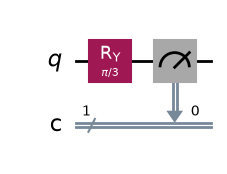

In [5]:

# Create a circuit with exactly 1 qubit and 1 classical bit
qc1 = QuantumCircuit(1, 1)

# Rotate the qubit by 60 degrees
theta1 = math.pi / 3
qc1.ry(theta1, 0)

# Measure the qubit
qc1.measure(0, 0)

# Display the circuit
qc1.draw("mpl")

In [6]:

# Create the simulator
simulator = AerSimulator()

# Compile the circuit for the simulator
compiled_qc1 = transpile(qc1, simulator)

# Run exactly 100 shots
job1 = simulator.run(compiled_qc1, shots=100)

# Retrieve measurement counts
result1 = job1.result()
counts1 = result1.get_counts()

print("Measurement results:", counts1)
print("Number of 0 outcomes:", counts1.get("0", 0))
print("Number of 1 outcomes:", counts1.get("1", 0))

Measurement results: {'0': 74, '1': 26}
Number of 0 outcomes: 74
Number of 1 outcomes: 26


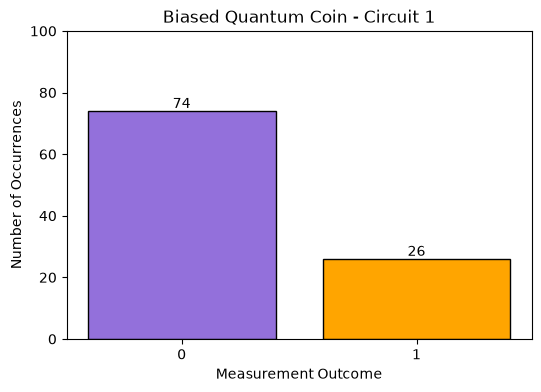

In [7]:

# Ensure both outcomes appear, even if one has zero counts
outcomes = ["0", "1"]
frequencies = [counts1.get(bit, 0) for bit in outcomes]

plt.figure(figsize=(6, 4))
bars = plt.bar(
    outcomes,
    frequencies,
    color=["mediumpurple", "orange"],
    edgecolor="black"
)

plt.title("Biased Quantum Coin - Circuit 1")
plt.xlabel("Measurement Outcome")
plt.ylabel("Number of Occurrences")
plt.xticks([0, 1], ["0", "1"])
plt.ylim(0, 100)

# Display the count above each bar
for bar, count in zip(bars, frequencies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        count + 1,
        str(count),
        ha="center"
    )

plt.show()

In [8]:

total_shots = sum(counts1.values())

percent_0 = counts1.get("0", 0) / total_shots * 100
percent_1 = counts1.get("1", 0) / total_shots * 100

print(f"Probability estimate for 0: {percent_0:.1f}%")
print(f"Probability estimate for 1: {percent_1:.1f}%")

Probability estimate for 0: 74.0%
Probability estimate for 1: 26.0%


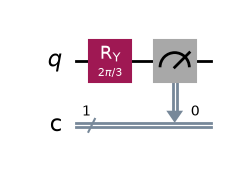

In [9]:

# Create a second circuit: 1 qubit, 1 classical bit
qc2 = QuantumCircuit(1, 1)

# Rotate by 120 degrees instead of 60 degrees
theta2 = 2 * math.pi / 3
qc2.ry(theta2, 0)

# Measure the qubit
qc2.measure(0, 0)

# Display the second circuit
qc2.draw("mpl")

In [10]:

compiled_qc2 = transpile(qc2, simulator)

job2 = simulator.run(compiled_qc2, shots=100)
result2 = job2.result()
counts2 = result2.get_counts()

print("Second circuit results:", counts2)
print("Number of 0 outcomes:", counts2.get("0", 0))
print("Number of 1 outcomes:", counts2.get("1", 0))

Second circuit results: {'1': 76, '0': 24}
Number of 0 outcomes: 24
Number of 1 outcomes: 76


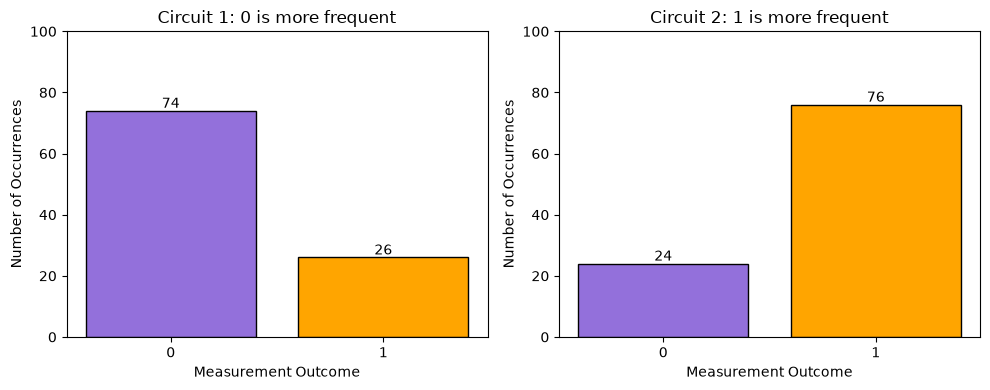

In [11]:

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

datasets = [
    (counts1, "Circuit 1: 0 is more frequent"),
    (counts2, "Circuit 2: 1 is more frequent")
]

for ax, (counts, title) in zip(axes, datasets):
    values = [counts.get("0", 0), counts.get("1", 0)]

    bars = ax.bar(
        ["0", "1"],
        values,
        color=["mediumpurple", "orange"],
        edgecolor="black"
    )

    ax.set_title(title)
    ax.set_xlabel("Measurement Outcome")
    ax.set_ylabel("Number of Occurrences")
    ax.set_ylim(0, 100)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 1,
            str(value),
            ha="center"
        )

plt.tight_layout()
plt.show()

### Challenge Question: How can quantum gates change the probability of obtaining 0 or 1 when a qubit is measured?

Quantum gates change the quantum state of a qubit, which changes the probabilities of measuring 0 or 1. For example, the \(R_Y(\theta)\) rotation gate changes the amplitudes of the qubit's state according to the rotation angle.

In my first circuit, I used an \(R_Y(\pi/3)\) gate. This gives a theoretical probability of 75% for measuring 0 and 25% for measuring 1.

In my second circuit, I used an \(R_Y(2\pi/3)\) gate. This gives a theoretical probability of 25% for measuring 0 and 75% for measuring 1.

After running 100 shots for each circuit, I compared the measurement counts and histograms. The results demonstrate that changing the quantum gate angle changes the measurement probability distribution. The observed counts may differ slightly from the theoretical probabilities because of random sampling.
